# Tutorial: reading retained runs

## Introduction

This notebook demonstrates the common writer/reader contract using small real pipeline runs. It distinguishes evaluated peptides, the final graph batch, measurements, provenance and replay, then reads the same data individually and as a collection. No custom scoring or analysis algorithm is implemented here.

### Library abstraction

`Pipeline.run()` creates a `RunResult`; its `AnalysisReader` accesses one run lazily. A persistent bundle contains `results.sqlite` and `settings.json`. `ExperimentReader` discovers bundles and applies collection selections through the same logical tables. Opening a reader does not rerun inference.

### Assumptions and notation

The examples use the bundled `article_25` HydrAMP model on CPU, seed 7, and a deterministic hydrophobicity objective. 

During tutorial we use following definitions:
- `node_id` is a graph placement, 
- `execution_id` one invocation, 
- `candidate_id` a generated occurrence, 
- `peptide_id` a unique retained sequence. 
  
> Remark:
> 
> A scored sequence may occur in multiple candidates. Small actual runs create the input data; temporary directories are cleaned at the end.

### Tutorial dependencies

From the repository root: `uv sync --extra cpu`. The default HydrAMP weights are bundled; `bash assets/scripts/downloads/hydraAMP/download_hydramp_model.sh` checks them. No APEX weights or external peptide dataset are needed.

In [1]:
# USAGE: Import the writer and both reader entry points.
from pathlib import Path
from tempfile import TemporaryDirectory
import pandas as pd
from IPython.display import display
from pep_compass import Pipeline
import pep_compass.steps as ps  # ps - PipelineSteps
import pep_compass.autoencoder as ae
from pep_compass.optimization.saving import AnalysisReader, DataUnavailableError
from pep_compass.analysis.reader import ExperimentReader

artifacts = TemporaryDirectory(prefix="pep-compass-reader-")
root = Path(artifacts.name)
inputs = ["FLYKWWIRIGRLKL"]

/home/max/repositories/pep-compass/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Create the source data

### Relation between components

The graph generates a small candidate pool, deduplicates sequences, evaluates the pool, labels that evaluated batch and keeps one row as the final graph output. This makes the two result concepts observable: the evaluated archive remains complete after the downstream filter reduces the output. All numerical work is performed by library components.

### Cells

Create the same graph once, then run it in memory and persistently with identical seed/retention. An explicit Snapshot requires `boundaries` or `trajectories`. The snapshot references an existing retained batch, rather than a separate copy of its contents.

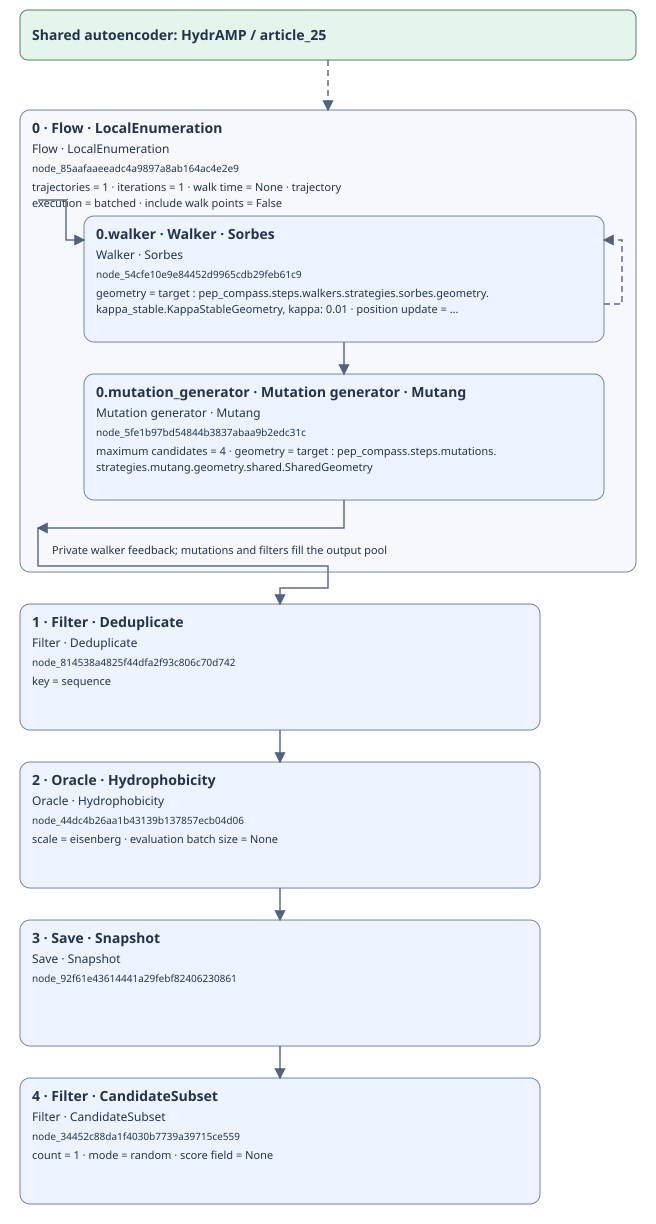

{'status': 'completed',
 'duration_seconds': 0.590382310008863,
 'oracle_calls': 4,
 'generated_candidates': 4,
 'completed_iterations': 1,
 'iteration_events': 1,
 'objective_name': 'hydrophobicity',
 'terminal_count': 1,
 'error': None,
 'best_sequence': 'FLYKWWIRIGRLWL',
 'best_score': 0.28357142857142853}

In [2]:
# USAGE: Generate a small real run; keep all measurements and reconstruction explicit.
pipeline = Pipeline([
    ps.flow.LocalEnumeration(
        walker=ps.walkers.Sorbes(),
        mutation_generator=ps.mutations.Mutang(maximum_candidates=4),
        trajectories=1, iterations=1, include_walk_points=False,
    ),
    ps.filters.Deduplicate(),
    ps.oracles.Hydrophobicity(),
    ps.saving.Snapshot("evaluated-pool"),
    ps.filters.CandidateSubset(count=1),
], autoencoder=ae.HydrAMP(jacobian_mode="approx"))
pipeline.set_runner_settings(
    execution={"seed": 7, "device": "cpu"},
    storage={"reconstruction": "trajectories", "metrics_level": "basic_and_components",
             "component_data": "summary", "save_lineage": True},
)
display(pipeline.show())
memory_result = pipeline.run(inputs)
display(memory_result.summary)

## One run: evaluations and final output

### Data contract

`get_evaluations()` returns actual scoring records; cache hits do not create synthetic records. `get_archive()` returns the unique objective/sequence view of those facts. `get_final_batch()` returns the actual root output, which may be smaller. No option discards a completed evaluation. `latent_origins` records generating coordinates and is not necessarily the encoding of a mutant sequence.

### Cells

Read each representation, verify the post-selection difference, and read the named snapshot from before final filtering.

In [3]:
# USAGE: Compare actual evaluations, unique archive and the final graph batch.
reader = memory_result.reader
evaluations = reader.get_evaluations()
archive = reader.get_archive()
final_batch = reader.get_final_batch()
display(evaluations)
display(archive)
print("Evaluated unique peptides:", len(archive))
print("Final graph sequences:", final_batch.sequences)
assert len(archive) > len(final_batch) == 1
snapshot_batches = reader.get_snapshot("evaluated-pool")
assert snapshot_batches[0].sequences == tuple(evaluations.sequence)
assert set(final_batch.sequences).issubset(set(archive.sequence))

,evaluation_id,objective,sequence,score,direction,evaluation_index,candidate_id,execution_id,iteration_id
0,1,hydrophobicity,FLYKWWIRIGRLKL,0.118571,maximize,0,2,10,None
1,2,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,1,3,10,None
2,3,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,2,4,10,None
3,4,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,3,5,10,None


,evaluation_id,objective,sequence,score,direction,evaluation_index,candidate_id,execution_id,iteration_id
0,1,hydrophobicity,FLYKWWIRIGRLKL,0.118571,maximize,0,2,10,None
1,2,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,1,3,10,None
2,3,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,2,4,10,None
3,4,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,3,5,10,None


Evaluated unique peptides: 4
Final graph sequences: ('FLYKWWPRIGRLKL',)


## Measurements, artifacts and lineage

### Data contract

`step_executions` records invocations, `iterations` nested iterations, and `execution_metrics` aggregated internal stages. Durations are host wall time with observation overhead. RSS is sampled process-wide every 10 ms and at boundaries; it is not exact component allocation or VRAM. `component_records` contains descriptive artifacts instead of measurement columns. Lineage relates ordered batch positions, using pairwise or singleton-parent broadcast ranges.

### Cells

Project only useful columns and stream bounded chunks through `TableHandle.scan`. Materializing a small table with pandas is an explicit presentation operation, not a requirement of the reader.

In [4]:
# USAGE: Scan selected columns without materializing all tensor payloads.
execution_table = reader.tables["step_executions"]
columns = ["execution_id", "node_id", "parent_execution_id", "iteration_id", "phase",
           "input_count", "output_count", "duration_seconds", "memory_peak_bytes", "status"]
for chunk in execution_table.scan(columns, chunk_size=8):
    display(chunk)
for table_name in ("iterations", "execution_metrics"):
    table = reader.tables[table_name]
    display(pd.concat(table.scan(table.columns, chunk_size=100), ignore_index=True))
display(reader.get_component_data())
display(reader.get_lineage())
assert reader.tables["execution_metrics"].count_rows() > 0

,execution_id,node_id,parent_execution_id,iteration_id,phase,input_count,output_count,duration_seconds,memory_peak_bytes,status
0,0,root,NaN,NaN,precompute,NaN,NaN,0.000987,615006208,completed
1,1,node_e450705d8cd54bef86bd257de1ec944f,0.0,NaN,precompute,NaN,NaN,0.000300,615006208,completed
2,2,node_e450705d8cd54bef86bd257de1ec944f,1.0,NaN,precompute,NaN,NaN,0.000057,614940672,completed
3,3,node_681e619295244d4aaa40b883cf66f436,0.0,NaN,precompute,NaN,NaN,0.000241,615006208,completed
4,4,root,NaN,NaN,execute,1.0,1.0,0.205538,647507968,completed
5,5,node_e450705d8cd54bef86bd257de1ec944f,4.0,NaN,execute,1.0,4.0,0.186055,647290880,completed
6,6,node_8d5bf60c7e0c40f8911774b9fe76dd6f,5.0,1.0,execute,1.0,1.0,0.124556,642174976,completed
7,7,node_5be59ee8cebb4bc5ba3d46a48657281c,5.0,1.0,execute,1.0,4.0,0.020321,647012352,completed


,execution_id,node_id,parent_execution_id,iteration_id,phase,input_count,output_count,duration_seconds,memory_peak_bytes,status
0,8,node_e450705d8cd54bef86bd257de1ec944f,5,1.0,execute,4,4,0.011258,647024640,completed
1,9,node_d0761156e18a46578e4e8ee1f0a044df,4,NaN,execute,4,4,0.002446,647294976,completed
2,10,node_681e619295244d4aaa40b883cf66f436,4,NaN,execute,4,4,0.003126,647405568,completed
3,11,node_62cfd881dd09477082b97234cbfe67f0,4,NaN,execute,4,4,0.004139,647413760,completed
4,12,node_268ad686fa92495799919303c742974f,4,NaN,execute,4,1,0.001426,647507968,completed


,iteration_id,loop_execution_id,parent_iteration_id,node_id,iteration_index,scope_json,trajectories,elapsed_seconds,duration_seconds,interval_seconds,step_duration_sum_seconds,memory_start_bytes,memory_peak_bytes,memory_end_bytes,input_count,output_count,status
0,1,5,None,node_e450705d8cd54bef86bd257de1ec944f,0,"{""path"": [""Flow"", ""LocalEnumeration"", ""branch[...",1,0.20463,0.179936,None,0.156135,616157184,647286784,647286784,1,4,completed


,metric_id,execution_id,iteration_id,stage_name,duration_seconds,memory_start_bytes,memory_peak_bytes,memory_end_bytes,input_count,output_count,status
0,1,6,1.0,input_geometry,0.049635,616161280,632422400,632422400,1,1.0,completed
1,2,6,1.0,directions,0.000803,632553472,633159680,633159680,1,1.0,completed
2,3,6,1.0,scaling,0.000233,633159680,633425920,633425920,1,1.0,completed
3,4,6,1.0,acceleration,0.012592,633425920,633634816,633634816,1,1.0,completed
4,5,6,1.0,position_update,0.002234,633634816,633634816,633634816,1,1.0,completed
5,6,6,1.0,boundary,0.000299,633634816,633831424,633831424,1,1.0,completed
6,7,6,1.0,output_geometry,0.017382,633831424,637444096,637444096,1,1.0,completed
7,8,7,1.0,geometry,0.000116,642183168,642183168,642183168,1,1.0,completed
8,9,7,1.0,directions,0.000190,642183168,642183168,642183168,1,NaN,completed
9,10,7,1.0,scoring,0.000243,642183168,642248704,642248704,1,NaN,completed


,record_id,node_id,execution_id,name,payload_id,data
0,1,node_8d5bf60c7e0c40f8911774b9fe76dd6f,6,Sorbes,4148b708c682ca41f3d9722911b519949d114adc9d2818...,{'geometry': {'_target_': 'pep_compass.steps.w...
1,2,node_5be59ee8cebb4bc5ba3d46a48657281c,7,Mutang,0acce1925ae47f42557e8b95729ea45ae251e8ed7a8d6b...,"{'maximum_candidates': 4, 'geometry': {'_targe..."
2,3,node_e450705d8cd54bef86bd257de1ec944f,8,Flow,748f9502391386d7c90056bd76194f86f237ea8dc88633...,{}
3,4,node_e450705d8cd54bef86bd257de1ec944f,5,LocalEnumeration,fec2659a4f24309efc2cfe51aaf99f3f0d54583462fb2b...,"{'trajectories': 1, 'iterations': 1, 'walk_tim..."
4,5,node_d0761156e18a46578e4e8ee1f0a044df,9,Deduplicate,714d6f4feb5c4a885c5698b5d7c9212f2bc512ff987872...,{'key': 'sequence'}
5,6,node_681e619295244d4aaa40b883cf66f436,10,Hydrophobicity,f1c09745416001ca731b8e3a7376af24a95a50bbfe391f...,"{'scale': 'eisenberg', 'evaluation_batch_size'..."
6,7,node_62cfd881dd09477082b97234cbfe67f0,11,Snapshot,748f9502391386d7c90056bd76194f86f237ea8dc88633...,{}
7,8,node_268ad686fa92495799919303c742974f,12,CandidateSubset,203fd57de35abb5dab19a91b595499002ff3f2b186712a...,"{'count': 1, 'mode': 'random', 'score_field': ..."
8,9,None,4,Flow,748f9502391386d7c90056bd76194f86f237ea8dc88633...,{}


,lineage_id,child_batch_id,child_start,child_end,parent_batch_id,parent_start,parent_end,mapping_kind,execution_id,iteration_id
0,1,2,0,1,1,0,1,pairwise,5,1.0
1,2,3,0,1,2,0,1,pairwise,6,1.0
2,3,4,0,4,3,0,1,broadcast,7,1.0
3,4,5,0,4,4,0,4,pairwise,5,NaN
4,5,6,0,4,5,0,4,pairwise,9,NaN
5,6,7,0,4,6,0,4,pairwise,10,NaN
6,7,8,0,1,7,2,3,pairwise,12,NaN


## Persistent bundles and export

### Data contract

`RunResult.save(path)` exports already retained information. It cannot recover data omitted during execution. Persistent writes and exported memory databases use the same schema; the destination is a new directory and is not overwritten. A reader context manager closes its connection; closing a result closes the reader it owns.

### Cells

Export memory data, produce a separate persistent run, and compare their evaluated tables with the memory source.

In [5]:
# USAGE: Export without inference, then independently exercise direct SQLite writing.
exported_path = memory_result.save(root / "exported-memory")
disk_result = pipeline.run(inputs, storage={"backend": "sqlite", "path": str(root / "disk-run")})
assert (exported_path / "settings.json").is_file()
assert (exported_path / "results.sqlite").is_file()
with AnalysisReader(exported_path) as exported:
    pd.testing.assert_frame_equal(archive, exported.get_archive())
    assert exported.get_final_batch().sequences == final_batch.sequences
pd.testing.assert_frame_equal(archive, disk_result.reader.get_archive())
print("Run directories:", exported_path, disk_result.path)

Run directories: /tmp/pep-compass-reader-3jss49wj/exported-memory /tmp/pep-compass-reader-3jss49wj/disk-run


## Supported reconstruction and missing data

### Data contract

`boundaries` retains supported LocalEnumeration input/state/RNG checkpoints. `trajectories` includes those boundaries plus step batches, walker points and the actual graph output. Replay is explicit: it verifies source/model identity, restores the historical evaluation prefix and supported RNGs, executes the selected fragment and compares ordered sequence count/digest. It does not implicitly rerun downstream oracles. `none` retains mandatory evaluations and requested structural lineage, but not reconstruction payloads.

### Cells

Replay one saved boundary and inspect walker points. A second graph without Snapshot demonstrates an intentional missing-data error for base retention.

In [6]:
# USAGE: Reconstruct only a declared supported boundary.
checkpoints = reader.get_checkpoints()
display(checkpoints)
checkpoint_id = int(checkpoints.iloc[0]["checkpoint_id"])
replayed = reader.reconstruct_local_enumeration(checkpoint_id)
assert replayed.matches
points, positions = reader.get_trajectories()
display(points)
assert len(points) == len(positions)

# USAGE: Missing reconstruction raises explicitly; evaluated results remain readable.
base_pipeline = Pipeline([ps.oracles.Hydrophobicity()], autoencoder=ae.HydrAMP(jacobian_mode="approx"))
base_result = base_pipeline.run(inputs, seed=7)
assert len(base_result.reader.get_archive()) == 1
try:
    base_result.reader.get_final_batch()
except DataUnavailableError as error:
    print("Expected missing-retention error:", error)
else:
    raise AssertionError("Base retention unexpectedly supplied a final batch.")

,checkpoint_id,node_id,execution_id,iteration_id,scope_json,phase,payload_id,output_count,output_sha256
0,1,node_e450705d8cd54bef86bd257de1ec944f,5,None,"{""path"": [""Flow"", ""LocalEnumeration""], ""loop_i...",before_prepare_call,368367741da7fd8b72ec7283d0acb8f4d31b07ea97dd2a...,4,9bcd1888563fb9aa35194c0dfe4f9b78e37665e795580b...


,execution_id,sequence,latent_index,trajectory_id,trajectory_index,trajectory_step,candidate_id
0,6,FLYKWWIRIGRLKL,0,Flow/LocalEnumeration/branch[batched_trajector...,0,0,1


Expected missing-retention error: Enable reconstruction='trajectories' to retain the graph output.


## Collections and portable tables

### Relation between components

`ExperimentReader` discovers bundles under one root without rebuilding their graphs. Selections identify runs, and `collect` projects the same logical tables while adding collection metadata. CSV is suitable for an evaluated table; it does not preserve replay/tensor payloads. Keep the complete bundle when reconstruction is needed.

### Cells

Select both saved seed-7 bundles, collect a small table, and export that table with the public schema snapshot.

In [7]:
# USAGE: Both bundles share one table contract and one collection selection.
collection = ExperimentReader(root)
selected = collection.select(seeds=[7])
combined = selected.collect("evaluation_archive", columns=["sequence", "score", "seed"])
display(combined)
assert len(combined) == 2 * len(archive)
combined.to_csv(root / "evaluated.csv", index=False)
pipeline.save_schema(root / "pipeline.json")

# USAGE: Close owned readers before deleting their temporary files.
for result in (memory_result, disk_result, base_result):
    result.close()
artifacts.cleanup()

,sequence,score,seed
0,FLYKWWIRIGRLKL,0.118571,7
1,FLYKWWIRIGRLWL,0.283571,7
2,FLYKWWPRIGRLKL,0.027143,7
3,FLYKWWPRIGRLWL,0.192143,7
4,FLYKWWIRIGRLKL,0.118571,7
5,FLYKWWIRIGRLWL,0.283571,7
6,FLYKWWPRIGRLKL,0.027143,7
7,FLYKWWPRIGRLWL,0.192143,7
